# Practical 11 – Random Forest Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay


In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, pos_label=0), 'Recall': recall_score(y_test, pred, pos_label=0), 'F1': f1_score(y_test, pred, pos_label=0)}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=['Malignant', 'Benign']))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Malignant', 'Benign'])
    plt.title(name)
    plt.show()
    return scores


Random Forest {'Accuracy': 0.956140350877193, 'Precision': 0.9512195121951219, 'Recall': 0.9285714285714286, 'F1': 0.9397590361445783}
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



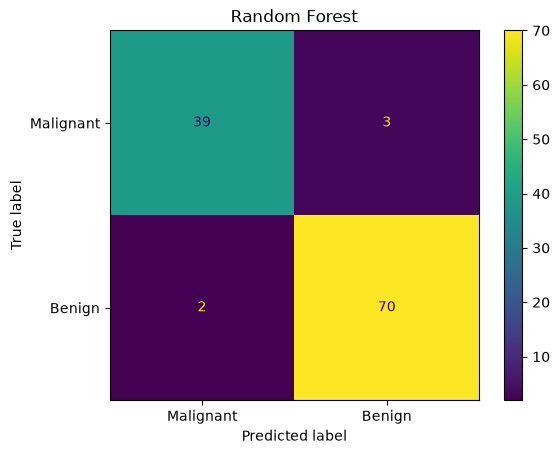

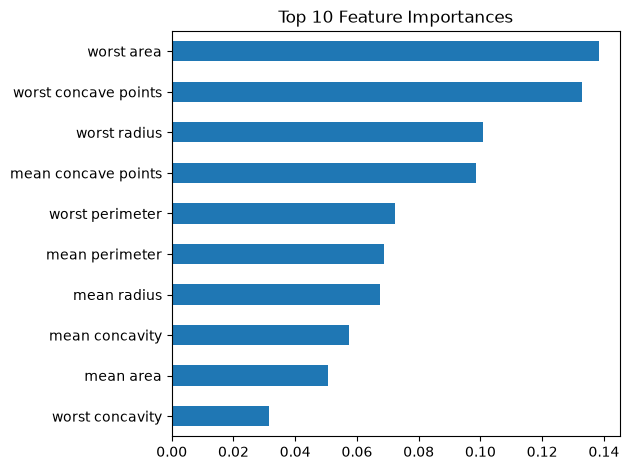

In [4]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
evaluate('Random Forest', model)
importance = pd.Series(model.feature_importances_, index=X.columns).nlargest(10).sort_values()
importance.plot.barh(title='Top 10 Feature Importances')
plt.tight_layout()
plt.show()
